# Mathematical Modeling and Design of a Reinforced Concrete Beam according to Eurocode 2

**SoftUni – Math Concepts for Developers**
**Date:** October 2026

## 1. Introduction and Problem Statement

This project presents a complete workflow for the design of a simply supported reinforced concrete beam according to Eurocode 2 (EN 1992-1-1).

The main goals are:
- To demonstrate the relationship between statics and calculus (derivatives of internal forces)
- To implement the flexural and shear design procedures of EC2 in clean, readable Python
- To validate the results against an existing Mathcad calculation
- To perform parametric studies and visualize the behavior of the beam

The project follows the scientific approach: problem formulation → mathematical model → implementation → validation → analysis.

## 2. Input Data

We start with the geometry, material properties and loading of the beam.

In [1]:
# Geometry
b = 300          # mm - beam width
h = 450          # mm - beam height
l = 6000         # mm - span length
cnom = 35        # mm - concrete cover
link = 8         # mm - diameter of links
phi = 20         # mm - tension reinforcement diameter
phi_comp = 14    # mm - compression reinforcement diameter
dg = 20          # mm - maximum aggregate size

# Materials
fck = 30         # MPa - concrete C30/37
fyk = 500        # MPa - characteristic yield strength of reinforcement
fywk = 500       # MPa - characteristic yield strength of shear reinforcement
gamma_c = 1.5    # partial factor for concrete
gamma_s = 1.15   # partial factor for steel

# Design strengths
fyd = fyk / gamma_s
fywd = fywk / gamma_s

# Loading
gk = 20        # kN/m - permanent load (SLS)
qk = 10        # kN/m - variable load (SLS)

# Other
delta = 0.85     # redistribution ratio

print("Input data loaded successfully.")
print(f"Effective span l = {l} mm")
print(f"Design yield strength fyd = {fyd:.1f} MPa")

Input data loaded successfully.
Effective span l = 6000 mm
Design yield strength fyd = 434.8 MPa


## 3. Static Analysis and Differential Relationships

For a simply supported beam with uniformly distributed load $ q $, the internal forces are related through the following differential equations:

$$
\frac{dV}{dx} = -q(x)
$$

$$
\frac{dM}{dx} = V(x)
$$

These relationships come directly from equilibrium of an infinitesimal beam element.

**Important consequence:**
The bending moment $ M $ reaches an extremum (usually maximum) where the shear force $ V = 0 $.

We will:
1. Derive the analytical expressions for $ V(x) $ and $ M(x) $
2. Find the location and value of $ M_{\max} $ by setting $ V(x) = 0 $
3. Verify the derivative relationship numerically

### 3.1 Analytical solution

Total design load:
$$ q = 1.35 g_k + 1.5 q_k $$

Shear force:
$$ V(x) = \frac{q l}{2} - q x $$

Bending moment:
$$ M(x) = \frac{q l}{2} x - \frac{q x^2}{2} $$

Maximum moment ($ M_{Ed} $) occurs at midspan $x = l/2$:
$$ M_{\max} = \frac{q l^2}{8} $$

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Design load (ULS) [kN/m]
q = 1.35 * gk + 1.5 * qk
print(f"Design load q = {q:.2f} kN/m")

# Convert span to meters for convenience in diagrams
L = l / 1000  # m

# Analytical functions
def V(x):
    """Shear force in kN, x in meters"""
    return (q * L / 2) - q * x

def M(x):
    """Bending moment in kNm, x in meters"""
    return (q * L / 2) * x - (q * x**2) / 2

# Location of maximum moment (where V = 0)
x_max = L / 2
M_Ed = M(x_max)
V_Ed = q * L / 2

print(f"\nMaximum moment occurs at x = {x_max:.2f} m")
print(f"M_Ed = {M_Ed:.1f} kNm")
print(f"V_Ed = {V_Ed:.1f} kN")

Design load q = 42.00 kN/m

Maximum moment occurs at x = 3.00 m
M_Ed = 189.0 kNm
V_Ed = 126.0 kN


### 3.2 Numerical verification of the derivative relationship

We check that the numerical derivative of $ M(x) $ is approximately equal to $ V(x) $.

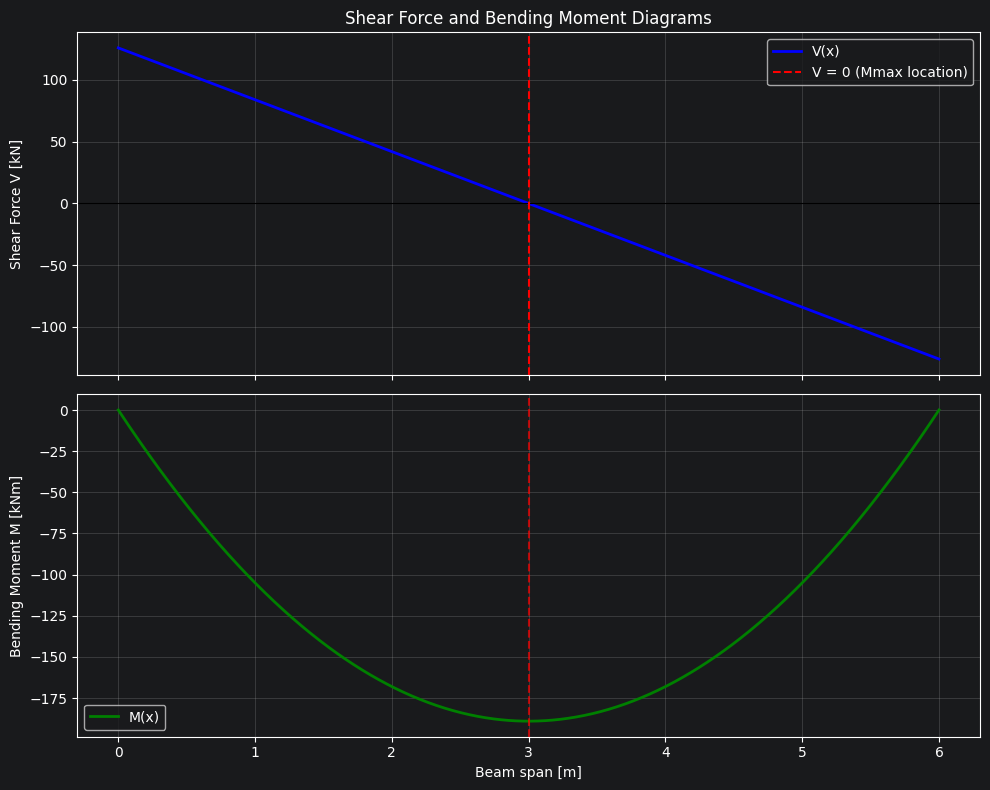

Max absolute difference between V(x) and dM/dx: 0.126126 kN


In [32]:
x = np.linspace(0, L, 1000)
V_values = V(x)
M_values = M(x)

# Numerical derivative of M
dM_dx = np.gradient(M_values, x)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize= (10, 8), sharex= True)

# Shear diagram
ax1.plot(x, V_values, 'b-', linewidth= 2, label= 'V(x)')
ax1.axhline(0, color= 'k', linewidth= 0.8)
ax1.axvline(x_max, color= 'r', linestyle= '--', label= 'V = 0 (Mmax location)')
ax1.set_ylabel('Shear Force V [kN]')
ax1.set_title('Shear Force and Bending Moment Diagrams')
ax1.legend()
ax1.grid(True, alpha= 0.3)

# Moment diagram
ax2.plot(x, -M_values, 'g-', linewidth= 2, label= 'M(x)')
# ax2.plot(x, -dM_dx, 'r--', linewidth= 1.5, label= 'Numerical dM/dx')
ax2.axvline(x_max, color= 'r', linestyle= '--', alpha= 0.7)
ax2.set_xlabel('Beam span [m]')
ax2.set_ylabel('Bending Moment M [kNm]')
ax2.legend()
ax2.grid(True, alpha= 0.3)

plt.tight_layout()
plt.show()

# Check how close the derivative is
print(f"Max absolute difference between V(x) and dM/dx: {np.max(np.abs(V_values - dM_dx)):.6f} kN")

The small difference between the analytical shear force and the numerical derivative of the moment confirms the fundamental relationship $ \frac{dM}{dx} = V $ and illustrates the accuracy of the numerical approximation.

## 4. Flexural Design

We now design the beam for the maximum bending moment obtained from the static analysis.

### 4.1 Effective depth

The effective depth $ d $ is calculated as:

$$
d = h - c_{nom} - \phi_{link} - \frac{\phi}{2}
$$

In [4]:
# Effective depth
d = h - cnom - link - phi / 2
d2 = cnom + link + phi_comp / 2   # distance to compression reinforcement

print(f"Effective depth d = {d:.0f} mm")
print(f"d2 = {d2:.0f} mm")

Effective depth d = 397 mm
d2 = 50 mm


### 4.2 Parameters K and K'

$$
K = \frac{M_{Ed}}{b d^2 f_{ck}}
$$

$$
K' = 0.6\delta - 0.18\delta^2 - 0.21
$$

If $ K \leq K' $, no compression reinforcement is required.

In [5]:
# K factor (note: units consistency - M in Nmm, b and d in mm, fck in MPa)
M_Ed_Nmm = M_Ed * 1e6          # convert kNm to Nmm
K = M_Ed_Nmm / (b * d**2 * fck)

K_prime = 0.6 * delta - 0.18 * delta**2 - 0.21

print(f"K = {K:.4f}")
print(f"K' = {K_prime:.4f}")

if K <= K_prime:
    print("→ No compression reinforcement required (K ≤ K')")
else:
    print("→ Compression reinforcement is required")

K = 0.1332
K' = 0.1700
→ No compression reinforcement required (K ≤ K')


### 4.3 Lever arm z and required reinforcement

The lever arm $ z $ is limited to $ 0.95d $.

Required tension reinforcement:
$$
A_{s,req} = \frac{M_{Ed}}{f_{yd} \cdot z}
$$

In [6]:
# Lever arm z
if K <= K_prime:
    z = min(d/2 * (1 + np.sqrt(1 - 3.53*K)), 0.95*d)
else:
    z = d/2 * (1 + np.sqrt(1 - 3.53*K_prime))

print(f"Lever arm z = {z:.0f} mm")

# Required tension reinforcement
As_req = (M_Ed_Nmm) / (fyd * z)   # mm²

print(f"Required tension reinforcement As,req = {As_req:.0f} mm²")

Lever arm z = 343 mm
Required tension reinforcement As,req = 1267 mm²


In [35]:
n_bars = 5  # Provided reinforcement: 5∅20; Change the number of steel bars (or the diameter) to meet the requirement
As_prov = n_bars * np.pi * (phi**2) / 4

print(f"Provided As = {As_prov:.0f} mm² ({n_bars}∅{phi})")

# Bending capacity
M_Rd = As_prov * z * fyd / 1e6   # kNm
print(f"M_Rd = {M_Rd:.1f} kNm")
print(f"M_Ed = {M_Ed:.1f} kNm")

if M_Rd >= M_Ed:
    print("→ Satisfactory")
else:
    print("→ The reinforcement is insufficient")

Provided As = 1571 mm² (5∅20)
M_Rd = 234.2 kNm
M_Ed = 189.0 kNm
→ Satisfactory


### 4.4 Minimum and maximum reinforcement

According to EC2:

$$
A_{s,\min} = \max\left(0.26\frac{f_{ctm}}{f_{yk}}b d,\ 0.0013 b d\right)
$$

$$
A_{s,\max} = 0.04\, b\, h
$$

In [8]:
# Mean tensile strength of concrete
fctm = 0.3 * fck**(2/3)

As_min = max(0.26 * (fctm / fyk) * b * d, 0.0013 * b * d)
As_max = 0.04 * b * h

print(f"fctm = {fctm:.2f} MPa")
print(f"As,min = {As_min:.0f} mm²")
print(f"As,max = {As_max:.0f} mm²")
print(f"As,prov = {As_prov:.0f} mm²")

if As_min <= As_prov <= As_max:
    print("→ Provided reinforcement is within limits")
else:
    print("→ Provided reinforcement is outside the allowed limits")

fctm = 2.90 MPa
As,min = 179 mm²
As,max = 5400 mm²
As,prov = 1571 mm²
→ Provided reinforcement is within limits


### 4.5 Bar spacing check

Clear spacing between bars must satisfy:

$$
a \geq \max(20\ \text{mm},\ \phi,\ d_g + 5\ \text{mm})
$$

In [38]:
# Clear spacing:
spacing = (b - 2*cnom - 2*link - n_bars*phi) / (n_bars - 1)
a_min = max(20, phi, dg + 5)

print(f"Clear spacing between bars = {spacing:.0f} mm")
print(f"Minimum required clear spacing = {a_min:.0f} mm")

if spacing >= a_min:
    print("→ Spacing is OK")
else:
    print("→ Spacing is insufficient")

Clear spacing between bars = 28 mm
Minimum required clear spacing = 25 mm
→ Spacing is OK


## 5. Shear Design

### 5.1 Shear resistance without shear reinforcement $ V_{Rd,c} $

$$
V_{Rd,c} = \left[ C_{Rd,c} \cdot k \cdot (100 \rho_l f_{ck})^{1/3} + k_1 \sigma_{cp} \right] b d
$$

with the minimum value:

$$
V_{Rd,c} \geq \nu_{\min} \cdot b \cdot d
$$

In [39]:
# Constants
CRd_c = 0.18 / gamma_c
k1 = 0.15
sigma_cp = 0          # no axial force

# k factor
k = min(1 + (200 / d)**0.5, 2.0)

# Longitudinal reinforcement ratio
rho_l = min(As_prov / (b * d), 0.02)

# Strength reduction factor
nu = 0.6 * (1 - fck / 250)

# Minimum shear stress
nu_min = 0.035 * k**(3/2) * fck**0.5

# Concrete shear resistance
VRd_c = (CRd_c * k * (100 * rho_l * fck)**(1/3) + k1 * sigma_cp) * b * d / 1000   # kN
VRd_c_min = nu_min * b * d / 1000  # kN

VRd_c = max(VRd_c, VRd_c_min)

print(f"k = {k:.2f}")
print(f"ρl = {rho_l:.4f}")
print(f"VRd,c = {VRd_c:.1f} kN")
print(f"VEd = {V_Ed:.1f} kN")

if VRd_c >= V_Ed:
    print("→ No shear reinforcement required")
else:
    print("→ Shear reinforcement is required")

k = 1.71
ρl = 0.0132
VRd,c = 83.3 kN
VEd = 126.0 kN
→ Shear reinforcement is required


### 5.2 Maximum shear resistance $ V_{Rd,\max} $

The angle of the compression strut $ \theta $ is limited between 30° and 45°.

$$
V_{Rd,\max} = \nu \cdot f_{cd} \cdot b \cdot z \cdot \frac{\cot\theta}{1 + \cot^2\theta}
$$

In [41]:
fcd = fck / gamma_c

# VRd,max for the limiting angles
theta_min = np.deg2rad(30)
theta_max = np.deg2rad(45)

VRd_max_30 = nu * fcd * b * z * np.cos(theta_min) * np.sin(theta_min) / 1000  # kN
VRd_max_45 = nu * fcd * b * z * np.cos(theta_max) * np.sin(theta_max) / 1000  # kN

print(f"VRd,max (θ=30°) = {VRd_max_30:.1f} kN")
print(f"VRd,max (θ=45°) = {VRd_max_45:.1f} kN")

VRd,max (θ=30°) = 470.5 kN
VRd,max (θ=45°) = 543.3 kN


### 5.3 Angle of the compression strut θ and required shear reinforcement

The strut angle θ is chosen between 30° and 45°.

If $ V_{Ed} \leq V_{Rd,\max}(30^\circ) $, we can use the minimum angle θ = 30°.

Required shear reinforcement:
$$
\frac{A_{sw}}{s} = \frac{V_{Ed}}{z \cdot f_{ywd} \cdot \cot\theta}
$$

In [42]:
# Determine theta
if V_Ed <= VRd_max_30:
    theta = np.deg2rad(30)
    print("θ = 30° (minimum angle)")
elif V_Ed <= VRd_max_45:
    # Solve for theta from VEd = VRd,max(theta)
    # Simplified approach using the formula from EC2
    cot_theta = np.sqrt( (nu * fcd * b * z / 1000) / V_Ed - 1 )
    theta = np.arctan(1 / cot_theta)
    print(f"θ = {np.rad2deg(theta):.1f}°")
else:
    print("VEd exceeds VRd,max – section size is insufficient")
    theta = None

if theta is not None:
    # Required Asw/s
    Asw_s_req = V_Ed * 1000 / (z * fywd * (1/np.tan(theta)))   # mm²/mm
    print(f"Required Asw/s = {Asw_s_req:.3f} mm²/mm")

θ = 30° (minimum angle)
Required Asw/s = 0.488 mm²/mm


In [43]:
# Chosen shear reinforcement:
n_legs = 2
phi_sw = 8   # mm; Change the links diameter if required
Asw = n_legs * np.pi * (phi_sw**2) / 4   # mm²

# Required spacing
s_req = Asw / Asw_s_req
s_max = min(0.75 * d, 600)

print(f"Asw = {Asw:.1f} mm² (for 2 shear legs ∅{phi_sw})")
print(f"Required spacing s_req = {s_req:.0f} mm")
print(f"Maximum allowed spacing s_max = {s_max:.0f} mm")

# Adopted spacing
s = 175   # mm (chosen); Adjust the spacing between the liks to meet the requirement

# Provided Asw/s
Asw_s_prov = Asw / s

print(f"\nAdopted spacing s = {s} mm")
print(f"Provided Asw/s = {Asw_s_prov:.3f} mm²/mm")

# Minimum shear reinforcement
rho_w_min = 0.08 * np.sqrt(fck) / fyk
rho_w = Asw / (b * s)

print(f"\nρw = {rho_w*100:.2f}%")
print(f"ρw,min = {rho_w_min*100:.2f}%")

# Shear resistance with reinforcement
VRd_s = (Asw / s) * z * fywd * (1/np.tan(theta)) / 1000   # kN

print(f"\nVRd,s = {VRd_s:.1f} kN")
print(f"VEd = {V_Ed:.1f} kN")

if VRd_s >= V_Ed and s <= s_max and rho_w >= rho_w_min:
    print("→ Shear design is OK")
else:
    print("→ Shear design needs adjustment")

Asw = 100.5 mm² (for 2 shear legs ∅8)
Required spacing s_req = 206 mm
Maximum allowed spacing s_max = 298 mm

Adopted spacing s = 175 mm
Provided Asw/s = 0.574 mm²/mm

ρw = 0.19%
ρw,min = 0.09%

VRd,s = 148.4 kN
VEd = 126.0 kN
→ Shear design is OK


## 6. Deflection Control (Span-to-Depth Ratio)

Eurocode 2 allows a simplified check using the limiting span-to-depth ratio (Table 7.4N).

The basic ratio is modified according to the reinforcement ratio and the stress in the reinforcement under quasi-permanent loads.

In [14]:
# Reinforcement ratios
rho = As_prov / (b * d)          # actual tension reinforcement ratio
rho_0 = 1e-3 * np.sqrt(fck)      # reference reinforcement ratio
rho_prime = 0.0                  # no compression reinforcement required

print(f"ρ  = {rho:.4f}")
print(f"ρ0 = {rho_0:.4f}")

# Factor K (simply supported beam → K = 1.0)
K = 1.0

# Stress in reinforcement under characteristic load (simplified)
# Using the ratio of required/provided and load factors
sigma_s = (fyk / gamma_s) * (As_req / As_prov) * ((gk + qk) / (1.35*gk + 1.5*qk))
print(f"σs ≈ {sigma_s:.0f} MPa")

ρ  = 0.0132
ρ0 = 0.0055
σs ≈ 251 MPa


In [15]:
# Limiting span/depth ratio
if rho <= rho_0:
    l_d_lim = K * (11 + 1.5*np.sqrt(fck)*rho_0/rho + 3.2*np.sqrt(fck)*(rho_0/rho - 1)**(3/2))
else:
    l_d_lim = K * (11 + 1.5*np.sqrt(fck)*rho_0/(rho - rho_prime) + (1/12)*np.sqrt(fck)*np.sqrt(rho_prime/rho))

# Correction for steel stress
l_d_lim = l_d_lim * (310 / sigma_s)

# Actual span/depth ratio
l_d_actual = (l) / d          # both in mm

print(f"Limiting l/d = {l_d_lim:.1f}")
print(f"Actual   l/d = {l_d_actual:.1f}")

if l_d_actual <= l_d_lim:
    print("→ Deflection check is OK")
else:
    print("→ Deflection check is NOT satisfied")

Limiting l/d = 17.8
Actual   l/d = 15.1
→ Deflection check is OK


## 7. Summary of Design Results

The table below summarizes the main results of the static analysis and the EC2 design checks.

In [30]:
import pandas as pd

summary_data = {
    "Parameter": [
        "Design load q (ULS)",
        "Maximum moment M_Ed",
        "Maximum shear V_Ed",
        "Effective depth d",
        "Required tension reinforcement As,req",
        "Provided tension reinforcement As,prov",
        "Bending capacity M_Rd",
        "Concrete shear resistance V_Rd,c",
        "Required shear reinforcement Asw/s",
        "Provided shear reinforcement Asw/s",
        "Shear capacity V_Rd,s",
        "Limiting span/depth ratio",
        "Actual span/depth ratio"
    ],
    "Value": [
        f"{q:.2f} kN/m",
        f"{M_Ed:.1f} kNm",
        f"{V_Ed:.1f} kN",
        f"{d:.1f} mm",
        f"{As_req:.0f} mm²",
        f"{As_prov:.0f} mm²",
        f"{M_Rd:.1f} kNm",
        f"{VRd_c:.1f} kN",
        f"{Asw_s_req:.3f} mm²/mm",
        f"{Asw_s_prov:.3f} mm²/mm",
        f"{VRd_s:.1f} kN",
        f"{l_d_lim:.1f}",
        f"{l_d_actual:.1f}"
    ],
    "Status": [
        "—",
        "—",
        "—",
        "—",
        "—",
        "OK" if As_min <= As_prov <= As_max else "Check",
        "OK" if M_Rd >= M_Ed else "Not OK",
        "Shear reinf. required" if VRd_c < V_Ed else "OK",
        "—",
        "OK",
        "OK" if VRd_s >= V_Ed else "Not OK",
        "—",
        "OK" if l_d_actual <= l_d_lim else "Not OK"
    ]
}

df_summary = pd.DataFrame(summary_data)
display(df_summary)

,Parameter,Value,Status
0,Design load q (ULS),42.00 kN/m,—
1,Maximum moment M_Ed,189.0 kNm,—
2,Maximum shear V_Ed,126.0 kN,—
3,Effective depth d,397.0 mm,—
4,"Required tension reinforcement As,req",1267 mm²,—
5,"Provided tension reinforcement As,prov",1571 mm²,OK
6,Bending capacity M_Rd,234.2 kNm,OK
7,"Concrete shear resistance V_Rd,c",83.3 kN,Shear reinf. required
8,Required shear reinforcement Asw/s,0.488 mm²/mm,—
9,Provided shear reinforcement Asw/s,0.574 mm²/mm,OK


## 8. Parametric Study – Influence of Beam Height

We investigate how the required tension reinforcement $ A_{s,req} $ and the concrete shear resistance $ V_{Rd,c} $ change when the beam height $ h $ varies, while keeping all other parameters constant.

This helps to understand the sensitivity of the design to the chosen cross-section depth.

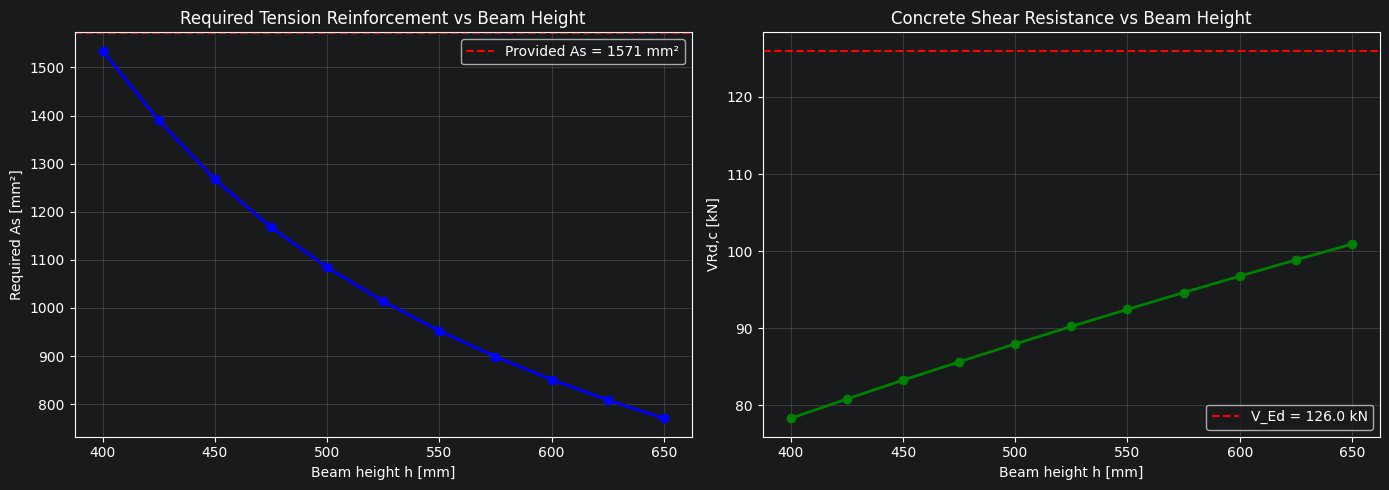

In [45]:
# Range of beam heights to study
h_values = np.arange(400, 651, 25)  # mm

As_req_list = []
VRd_c_list = []
d_list = []

for h_i in h_values:
    # Effective depth
    d_i = h_i - cnom - link - phi / 2
    d_list.append(d_i)

    # K factor
    M_Ed_Nmm = M_Ed * 1e6
    K_i = M_Ed_Nmm / (b * d_i**2 * fck)

    # Lever arm z
    if K_i <= K_prime:
        z_i = min(d_i/2 * (1 + np.sqrt(1 - 3.53*K_i)), 0.95*d_i)
    else:
        z_i = d_i/2 * (1 + np.sqrt(1 - 3.53*K_prime))

    # Required As
    As_req_i = M_Ed_Nmm / (fyd * z_i)
    As_req_list.append(As_req_i)

    # Shear resistance without links (simplified)
    k_i = min(1 + (200 / d_i)**0.5, 2.0)
    rho_l_i = min(As_prov / (b * d_i), 0.02)
    VRd_c_i = (CRd_c * k_i * (100 * rho_l_i * fck)**(1/3)) * b * d_i / 1000
    VRd_c_list.append(VRd_c_i)

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize= (14, 5))

ax1.plot(h_values, As_req_list, 'b-o', linewidth= 2)
ax1.axhline(As_prov, color= 'r', linestyle= '--', label= f'Provided As = {As_prov:.0f} mm²')
ax1.set_xlabel('Beam height h [mm]')
ax1.set_ylabel('Required As [mm²]')
ax1.set_title('Required Tension Reinforcement vs Beam Height')
ax1.grid(True, alpha= 0.3)
ax1.legend()

ax2.plot(h_values, VRd_c_list, 'g-o', linewidth= 2)
ax2.axhline(V_Ed, color= 'r', linestyle= '--', label= f'V_Ed = {V_Ed:.1f} kN')
ax2.set_xlabel('Beam height h [mm]')
ax2.set_ylabel('VRd,c [kN]')
ax2.set_title('Concrete Shear Resistance vs Beam Height')
ax2.grid(True, alpha= 0.3)
ax2.legend()

plt.tight_layout()
plt.show()

### Observations from the Parametric Study

- As the beam height $ h $ increases, the required tension reinforcement $ A_{s,req} $ decreases significantly. This is expected, because a larger effective depth $ d $ provides a greater lever arm $ z $ and reduces the normalized moment $ K $.
- The concrete shear resistance $ V_{Rd,c} $ increases almost linearly with $ h $, mainly due to the increase in the effective depth $ d $.
- For the current loading, a beam height of approximately 450–500 mm already provides a good balance between economy of reinforcement and shear capacity.
- Increasing the height beyond 550 mm brings diminishing returns in terms of reinforcement savings, while the self-weight of the beam continues to grow.

These results confirm that the choice of cross-section depth is one of the most influential parameters in the design of reinforced concrete beams.